# 02_4. Redundancy: correlation, VIF, mutual information, mRMR / Дублирование: корреляция, VIF, взаимная информация, mRMR

**EN.** Steps 4–5 of the methodology. Two features can each be strong but say the same thing (for example, the original and the current interest rate). Duplicates make a scorecard unstable (coefficients swap signs), make the neural network's job harder and make reason codes confusing ("rate" and "rate again"). We look for them among the features that passed steps 2 and 6–7:

- **Correlation of WoE values.** Every feature is replaced by the WoE of its train bin, so numeric and categorical features (and missing values) are on the same risk scale. Pearson correlation |ρ| > 0.7 = a redundant pair; **the feature with the larger IV stays** (unless a documented interpretability reason says otherwise).
- **Population.** The filter runs on the Y1 population (loans current at the observation date, DPD = 0, never in default before it) and only among features with IV ≥ 0.02.
- **VIF** (variance inflation factor) = 1 / (1 − R²), where R² is how well the other features explain this one. VIF 1 = independent; > 5 = noticeable overlap (warning); **> 10 = the feature is almost a combination of others → removed**, weakest first.
- **Mutual information (MI)** — how much knowing one variable reduces uncertainty about another; it also catches non-linear links. **mRMR** (minimum redundancy, maximum relevance) ranks features greedily: next = the one with the largest MI with the target minus its average MI with the features already chosen. It is used as a cross-check, not as an automatic filter.

Everything is computed on a 400,000-row train subsample (all events kept, weights rescaled).

**RU.** Шаги 4–5 методологии. Два признака могут быть сильными, но говорить одно и то же (например, ставка при выдаче и текущая ставка). Дубли делают скоринговую карту неустойчивой (коэффициенты меняют знак), усложняют работу нейросети и путают reason codes («ставка» и «снова ставка»). Ищем их среди признаков, прошедших шаги 2 и 6–7:

- **Корреляция WoE-значений.** Каждый признак заменяется на WoE своей корзины train, поэтому числовые и категориальные признаки (и пропуски) оказываются в одной шкале риска. Корреляция Пирсона |ρ| > 0,7 — пара дублей; **остаётся признак с бо́льшим IV** (если нет записанной причины интерпретируемости).
- **Популяция.** Фильтр работает на популяции Y1 (кредиты без просрочки на дату наблюдения, DPD = 0, не бывшие в дефолте до неё) и только среди признаков с IV ≥ 0,02.
- **VIF** (фактор инфляции дисперсии) = 1 / (1 − R²), где R² — насколько хорошо остальные признаки объясняют данный. VIF 1 — независим; > 5 — заметное пересечение (предупреждение); **> 10 — признак почти линейная комбинация других, удаляется**, начиная с самого слабого.
- **Взаимная информация (MI)** — насколько знание одной переменной уменьшает неопределённость другой; ловит и нелинейные связи. **mRMR** (минимальная избыточность, максимальная релевантность) упорядочивает признаки жадно: следующий — с наибольшей MI с целевой переменной минус средняя MI с уже выбранными. Используется как перекрёстная проверка, не как автоматический фильтр.

Всё считается на подвыборке train из 400 тыс. строк (все события сохранены, веса пересчитаны).

In [1]:
import warnings
warnings.filterwarnings("ignore")
import gc
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})

from xai_ews.config import feature_config
from xai_ews.data.features import COLUMNS
from xai_ews.features.data import TASKS, load_train, subsample
from xai_ews.features.redundancy import (correlated_pairs, greedy_decorrelate, mi_matrix, mrmr,
                                         mutual_info, select_per_task, vif_from_corr, weighted_corr)
from xai_ews.features.woe import load_binners
from xai_ews.paths import FEATURE_SELECTION_DIR, STAGE2_INTERIM_DIR

CFG = feature_config()
RULES = CFG["rules"]["redundancy"]
stab = pd.read_csv(FEATURE_SELECTION_DIR / "stability.csv")
uni = pd.read_csv(FEATURE_SELECTION_DIR / "univariate.csv")
CAND = stab.loc[stab["pass_steps_2_7"], "feature"].tolist()
iv = uni.pivot(index="feature", columns="task", values="iv_train").loc[CAND]
strength = iv.max(axis=1)
IV_MIN = CFG["rules"]["univariate"]["iv_min"]
print(len(CAND), "candidates after steps 2-7;", RULES)

36 candidates after steps 2-7; {'corr_max': 0.7, 'vif_max': 10, 'vif_warn': 5, 'sample_rows': 400000, 'strength': 'iv_max'}


### 1. WoE matrices, correlations and mutual information / Матрицы WoE, корреляции и взаимная информация

**EN.** Subsample train, transform the candidates to WoE with the train bins, compute the weighted correlation matrix, the MI of every feature with the label and the pairwise MI of the bins. A feature that is constant in the population has no correlation and is left out of the matrices.

**RU.** Подвыборка train, перевод кандидатов в WoE корзинами train, взвешенная корреляционная матрица, MI каждого признака с меткой и попарная MI корзин. Признак, постоянный в популяции, не имеет корреляции и исключается из матриц.

In [2]:
corr, rel, mi_pairs, mr, corr_sens = {}, {}, {}, {}, {}
stab_s = stab[stab["pass_iv_sens"] & stab["pass_stability_sens"] & stab["pass_sign"]]["feature"].tolist()
for task in TASKS:
    binners = load_binners(STAGE2_INTERIM_DIR / f"woe_binners_{task}.json")
    binners_s = load_binners(STAGE2_INTERIM_DIR / f"woe_binners_{task}_sens.json")
    tr = subsample(load_train(task, sorted(set(CAND) | set(stab_s))), task, RULES["sample_rows"], CFG["data"]["seed"])
    fs_s = [f for f in stab_s if binners_s[f].n_bins > 1]
    Xs = np.column_stack([binners_s[f].transform(tr[f].to_numpy()) for f in fs_s])
    corr_sens[task] = pd.DataFrame(weighted_corr(Xs, tr["sample_weight"].to_numpy().astype(np.float64)), index=fs_s, columns=fs_s)
    del Xs
    feats = [f for f in CAND if binners[f].n_bins > 1]
    y, w = tr[task].to_numpy(), tr["sample_weight"].to_numpy().astype(np.float64)
    X = np.column_stack([binners[f].transform(tr[f].to_numpy()) for f in feats])
    codes = np.column_stack([np.where((i := binners[f].bin_index(tr[f].to_numpy())) < 0, binners[f].n_bins, i)
                             for f in feats])
    corr[task] = pd.DataFrame(weighted_corr(X, w), index=feats, columns=feats)
    rel[task] = pd.Series([mutual_info(codes[:, j], y, w) for j in range(len(feats))], index=feats)
    mi_pairs[task] = pd.DataFrame(mi_matrix(codes, w), index=feats, columns=feats)
    mr[task] = mrmr(rel[task], mi_pairs[task])
    print(task, "rows", tr.height, "events", int(y.sum()), "features in matrix", len(feats))
    del tr, X, codes; gc.collect()

y1 rows 400000 events 14062 features in matrix 36


### 2. Correlation heatmap / Тепловая карта корреляций

**EN.** Absolute correlation of WoE values. Dark cells off the diagonal are candidate duplicates.

**RU.** Корреляция WoE-значений по модулю. Тёмные клетки вне диагонали — кандидаты в дубли.

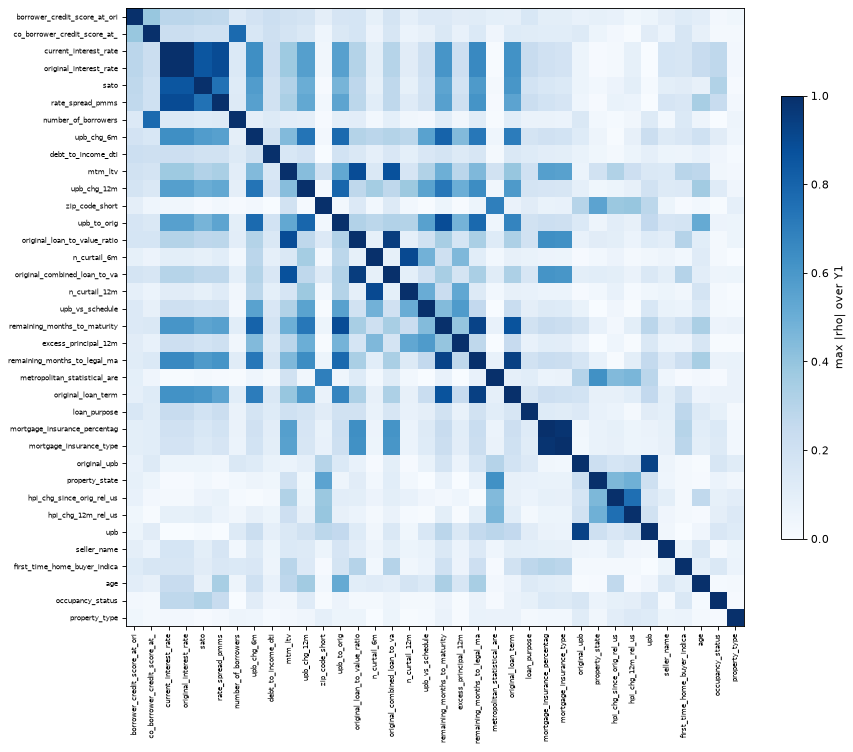

In [3]:
order = strength.sort_values(ascending=False).index.tolist()
both = pd.concat([corr[t].reindex(index=order, columns=order).abs() for t in TASKS]).groupby(level=0).max().reindex(index=order, columns=order)
fig, ax = plt.subplots(figsize=(11, 9.5))
im = ax.imshow(both.to_numpy(), cmap="Blues", vmin=0, vmax=1)
short = [f[:28] for f in order]
ax.set_xticks(range(len(order)), short, rotation=90, fontsize=6); ax.set_yticks(range(len(order)), short, fontsize=6)
ax.grid(False); plt.colorbar(im, ax=ax, fraction=0.03, label="max |rho| over " + ", ".join(t.upper() for t in TASKS)); plt.tight_layout(); plt.show()

In [4]:
pairs = pd.concat([correlated_pairs(corr[t], RULES["corr_max"]).assign(task=t) for t in TASKS])
pairs["iv_a"] = strength.reindex(pairs["a"]).to_numpy()
pairs["iv_b"] = strength.reindex(pairs["b"]).to_numpy()
pairs = pairs.sort_values("rho", key=np.abs, ascending=False)
print(f"pairs with |rho| > {RULES['corr_max']}: {len(pairs)}")
with pd.option_context("display.max_rows", 60):
    display(pairs.reset_index(drop=True))

pairs with |rho| > 0.7: 26


,a,b,rho,task,iv_a,iv_b
0,original_interest_rate,current_interest_rate,1.0000,y1,0.5543,0.5543
1,mortgage_insurance_percentage,mortgage_insurance_type,0.9813,y1,0.1064,0.1050
2,original_loan_to_value_ratio_ltv,original_combined_loan_to_value_ratio_cltv,0.9465,y1,0.2155,0.2114
3,original_loan_term,remaining_months_to_legal_maturity,0.9343,y1,0.1385,0.1546
4,original_upb,upb,0.9279,y1,0.1019,0.0631
5,remaining_months_to_maturity,remaining_months_to_legal_maturity,0.9231,y1,0.1918,0.1546
6,n_curtail_6m,n_curtail_12m,0.9000,y1,0.2128,0.2079
7,current_interest_rate,rate_spread_pmms,0.8908,y1,0.5543,0.4616
8,original_interest_rate,rate_spread_pmms,0.8908,y1,0.5543,0.4616
9,remaining_months_to_maturity,upb_to_orig,0.8896,y1,0.1918,0.2167


**EN. How to read.** There are 26 redundant pairs (|ρ| > 0.7), mostly inside two families:
- **Price of the loan:** original and current rate (ρ ≈ 1 — almost no modifications in train), SATO and the spread to PMMS (0.85–0.89 with the rates, 0.74 with each other): in 2013–2015 the market rate moved little, so all four measure the same thing.
- **Size, term and amortisation:** loan amount at origination and today (0.93), LTV / CLTV / mark-to-market LTV (0.87–0.95), the original term and the two remaining terms (0.87–0.93), and the amortisation block — balance changes over 6 and 12 months, balance / original balance and the remaining terms (0.70–0.89): a loan that amortises faster has both a shorter remaining term and a larger recent balance drop.
Others: the mortgage-insurance percentage and type (0.98: both say "insured or not"), the co-borrower score and the number of borrowers (0.77: a missing co-borrower score *means* one borrower), partial prepayments over 6 and 12 months (0.90), the two relative house-price changes (0.76). MSA and ZIP3 correlate at 0.69 — just below the threshold, so they are not a pair.

**RU. Как читать.** Пар дублей (|ρ| > 0,7) — 26, в основном внутри двух семейств:
- **Цена кредита:** ставка при выдаче и текущая (ρ ≈ 1 — модификаций в train почти нет), SATO и спред к PMMS (0,85–0,89 со ставками, 0,74 между собой): в 2013–2015 гг. рыночная ставка менялась мало, и все четыре признака измеряют одно и то же.
- **Размер, срок и погашение:** сумма при выдаче и текущий ОД (0,93), LTV / CLTV / текущий LTV (0,87–0,95), исходный срок и оба остатка срока (0,87–0,93), а также блок погашения — изменение ОД за 6 и 12 месяцев, ОД / исходный ОД и остатки срока (0,70–0,89): у кредита, который гасится быстрее, и остаток срока короче, и недавнее снижение ОД больше.
Прочие: процент и тип ипотечного страхования (0,98: оба говорят «застрахован или нет»), рейтинг созаёмщика и число заёмщиков (0,77: пустой рейтинг созаёмщика *означает* одного заёмщика), частичные досрочные погашения за 6 и 12 месяцев (0,90), два относительных изменения цен на жильё (0,76). MSA и ZIP3 коррелируют на 0,69 — чуть ниже порога, поэтому парой не считаются.

### 3. Removing duplicates: greedy pass by IV / Удаление дублей: жадный проход по IV

**EN.** Features are visited from the largest to the smallest IV. A feature is kept only if its |ρ| with every feature already kept is ≤ 0.7. `PREFER` lists the few pairs where a slightly weaker feature is kept for interpretability, each with its reason.

**RU.** Признаки перебираются от наибольшего IV к наименьшему. Признак остаётся, только если его |ρ| со всеми уже оставленными ≤ 0,7. `PREFER` — несколько пар, где ради интерпретируемости остаётся чуть более слабый признак; у каждой записана причина.

In [5]:
# Interpretability overrides: loser -> (winner, reason). Decided after looking at the pairs above.
PREFER = {
    "current_interest_rate": ("original_interest_rate",
        "IV 0.554 vs 0.554 (equal); the current rate differs only after a modification, which is almost "
        "absent in train; the original rate is static (needed for the H3 static set) and simpler to explain"),
    "zip_code_short": ("metropolitan_statistical_area_msa_or_metropolitan_statistical_division_area_msda",
        "applies only if the two form a correlated pair: train IV of ZIP3 is inflated by grouping ~890 categories "
        "on the train target (train 0.23, validation 0.07); MSA is coarser and easier to explain"),
}

In [6]:
kept, kept_t, red_log = select_per_task(corr, iv, CAND, IV_MIN, RULES["corr_max"], RULES["vif_max"],
                                        prefer={k: v[0] for k, v in PREFER.items()})
# joint rule (all tasks at once, strength = max IV), kept for comparison
kept_joint, _ = greedy_decorrelate(strength, [corr[t] for t in TASKS], RULES["corr_max"],
                                   prefer={k: v[0] for k, v in PREFER.items()})
print({t: len(k) for t, k in kept_t.items()}, "-> common set:", len(kept), f"(joint rule: {len(kept_joint)})")
red_log["iv_task"] = [iv.loc[f, t] if t in iv.columns else iv.loc[f].max() for f, t in zip(red_log["feature"], red_log["task"])]
red_log

{'y1': 21} -> common set: 21 (joint rule: 21)


,feature,kept_instead,rho,task,rule,iv_task
0,current_interest_rate,original_interest_rate,1.0000,y1,corr,0.5543
1,sato,original_interest_rate,0.8524,y1,corr,0.5011
2,rate_spread_pmms,original_interest_rate,0.8908,y1,corr,0.4616
3,number_of_borrowers,co_borrower_credit_score_at_origination,0.7743,y1,corr,0.4000
4,upb_chg_12m,upb_chg_6m,0.7381,y1,corr,0.2872
5,upb_to_orig,upb_chg_6m,0.7763,y1,corr,0.2167
6,original_loan_to_value_ratio_ltv,mtm_ltv,0.8895,y1,corr,0.2155
7,original_combined_loan_to_value_ratio_cltv,mtm_ltv,0.8725,y1,corr,0.2114
8,n_curtail_12m,n_curtail_6m,0.9000,y1,corr,0.2079
9,remaining_months_to_maturity,upb_chg_6m,0.8017,y1,corr,0.1918


**EN. How to read and conclusion.** 21 of the 36 features stay, 15 leave as duplicates:
- **Price:** `original_interest_rate` stays; `current_interest_rate` (|ρ| 1.00; IV 0.554 for both, i.e. equal — the `PREFER` override keeps the static, simpler original rate), `rate_spread_pmms` (0.89) and `sato` (0.85) leave.
- **Collateral:** `mtm_ltv` stays; original LTV (0.89) and CLTV (0.87) leave.
- **Amortisation and term:** `upb_chg_6m` (IV 0.35, the strongest of the block) stays and absorbs `upb_chg_12m` (0.74), `upb_to_orig` (0.78), `remaining_months_to_maturity` (0.80), `remaining_months_to_legal_maturity` (0.73) and `original_loan_term` (0.70).
- **Size:** `original_upb` stays, the current balance `upb` leaves (0.93).
- **Others:** `number_of_borrowers` (0.77 with the co-borrower score), `mortgage_insurance_type` (0.98 with the percentage), `n_curtail_12m` (0.90 with `n_curtail_6m`), `hpi_chg_12m_rel_us` (0.76 with `hpi_chg_since_orig_rel_us`).

`upb_vs_schedule` and `excess_principal_12m` stay (|ρ| ≤ 0.58 with any candidate). **ZIP3 and MSA both stay:** their |ρ| is 0.69, just below 0.7, so the `PREFER` entry for ZIP3 does not come into play. Note that the train IV of ZIP3 is inflated by grouping many categories on the train target (0.23 on train vs 0.07 on validation, below MSA's 0.09); the model-importance step will show whether both geography features are needed.

**RU. Как читать и вывод.** Из 36 признаков остаются 21, 15 выбывают как дубли:
- **Цена:** остаётся `original_interest_rate`; выбывают `current_interest_rate` (|ρ| 1,00; IV 0,554 у обоих, т. е. равны — правило `PREFER` оставляет статическую и более понятную ставку при выдаче), `rate_spread_pmms` (0,89) и `sato` (0,85).
- **Залог:** остаётся `mtm_ltv`; LTV (0,89) и CLTV (0,87) при выдаче выбывают.
- **Погашение и срок:** остаётся `upb_chg_6m` (IV 0,35, самый сильный в блоке) и заменяет `upb_chg_12m` (0,74), `upb_to_orig` (0,78), `remaining_months_to_maturity` (0,80), `remaining_months_to_legal_maturity` (0,73) и `original_loan_term` (0,70).
- **Размер:** остаётся `original_upb`, текущий ОД `upb` выбывает (0,93).
- **Прочие:** `number_of_borrowers` (0,77 с рейтингом созаёмщика), `mortgage_insurance_type` (0,98 с процентом страхования), `n_curtail_12m` (0,90 с `n_curtail_6m`), `hpi_chg_12m_rel_us` (0,76 с `hpi_chg_since_orig_rel_us`).

`upb_vs_schedule` и `excess_principal_12m` остаются (|ρ| ≤ 0,58 с любым кандидатом). **ZIP3 и MSA остаются оба:** их |ρ| = 0,69, чуть ниже 0,7, поэтому запись `PREFER` для ZIP3 не срабатывает. При этом IV ZIP3 на train завышен группировкой множества категорий по целевой переменной train (0,23 на train против 0,07 на validation, меньше, чем у MSA, 0,09); шаг важности в модели покажет, нужны ли оба географических признака.

### 4. VIF / VIF

**EN.** VIF is computed on the kept features (inside `select_per_task`, rule VIF > 10 → remove the weakest). Below: VIF of the kept set.

**RU.** VIF считается на оставленных признаках (внутри `select_per_task`, правило VIF > 10 → удалить самый слабый). Ниже — VIF оставленного набора.

In [7]:
vif = {}
for task in TASKS:
    fs = [f for f in kept if f in corr[task].index]
    vif[task] = pd.Series(vif_from_corr(corr[task].loc[fs, fs].to_numpy()), index=fs)
vif = pd.DataFrame(vif)
vif_log = red_log[red_log["rule"] == "vif"] if len(red_log) else red_log
print("removed by VIF:", vif_log["feature"].tolist() if len(vif_log) else "none")
print("max VIF of the common set:", vif.max().round(2).to_dict())
vif[(vif > RULES["vif_warn"]).any(axis=1)].round(2)

removed by VIF: none
max VIF of the common set: {'y1': 2.67}


,y1


**EN. How to read and conclusion.** After the correlation filter no feature has VIF > 5 (maximum 2.7, `upb_chg_6m`), so the VIF rule removes nothing.

**RU. Как читать и вывод.** После фильтра корреляций ни у одного признака VIF не превышает 5 (максимум 2,7 у `upb_chg_6m`), поэтому правило VIF ничего не удаляет.

### 4a. Static set for H3 / Статический набор для H3

**EN.** H3 compares a Y1 model on *static* features (origination data, including the loan amount `original_upb`, + geography) with a model on all selected features. If the static set were simply the static part of the final set, it would lose features that were dropped only because a *dynamic* twin is stronger (original LTV loses to mark-to-market LTV, the original term to the 6-month balance change). That would weaken the static baseline and make H3 easier to confirm. So the static set is selected on its own: static candidates that passed steps 2–7, with the same correlation and VIF rules applied **only among static features**.

**RU.** H3 сравнивает модель Y1 на *статических* признаках (данные при выдаче, включая сумму кредита `original_upb`, + география) с моделью на всех отобранных. Если взять статический набор просто как статическую часть итогового, он потеряет признаки, удалённые только потому, что сильнее их *динамический* двойник (LTV при выдаче проигрывает текущему LTV, исходный срок — изменению ОД за 6 мес.). Это ослабило бы статический эталон и облегчило бы подтверждение H3. Поэтому статический набор отбирается отдельно: статические кандидаты, прошедшие шаги 2–7, с теми же правилами корреляции и VIF, но **только среди статических признаков**.

In [8]:
from xai_ews.data.features import candidate_features
STATIC_POOL = [*candidate_features(static_only=True), "original_upb"]   # loan amount at origination
STATIC = [f for f in CAND if f in STATIC_POOL]
static_kept, static_t, static_log = select_per_task(corr, iv, STATIC, IV_MIN, RULES["corr_max"], RULES["vif_max"],
                                                    prefer={k: v[0] for k, v in PREFER.items()})
print(f"static candidates after steps 2-7: {len(STATIC)}; static set for H3: {len(static_kept)}")
print("dropped among static:", sorted(set(STATIC) - set(static_kept)))
print("static set:", static_kept)
print("static features of the main set:", [f for f in kept if f in STATIC])

static candidates after steps 2-7: 19; static set for H3: 16
dropped among static: ['mortgage_insurance_type', 'number_of_borrowers', 'original_combined_loan_to_value_ratio_cltv']
static set: ['borrower_credit_score_at_origination', 'co_borrower_credit_score_at_origination', 'debt_to_income_dti', 'first_time_home_buyer_indicator', 'original_interest_rate', 'original_upb', 'original_loan_term', 'original_loan_to_value_ratio_ltv', 'loan_purpose', 'seller_name', 'property_type', 'occupancy_status', 'mortgage_insurance_percentage', 'property_state', 'metropolitan_statistical_area_msa_or_metropolitan_statistical_division_area_msda', 'zip_code_short']
static features of the main set: ['borrower_credit_score_at_origination', 'co_borrower_credit_score_at_origination', 'debt_to_income_dti', 'first_time_home_buyer_indicator', 'original_interest_rate', 'original_upb', 'loan_purpose', 'seller_name', 'property_type', 'occupancy_status', 'mortgage_insurance_percentage', 'property_state', 'metropolit

**EN. Conclusion.** Of the 19 static candidates, 16 form the static set. It keeps original LTV and the original term, which the main set drops in favour of their dynamic twins (mark-to-market LTV, the 6-month balance change); the original rate and the loan amount `original_upb` are in both sets. Within the static features only true duplicates leave (CLTV vs LTV, insurance type vs percentage, number of borrowers vs co-borrower score); ZIP3 and MSA both stay (|ρ| 0.69). This set goes to `configs/features.yaml` as `static_h3`.

**RU. Вывод.** Из 19 статических кандидатов в статический набор входят 16. Он сохраняет LTV при выдаче и исходный срок, которые основной набор удаляет в пользу их динамических двойников (текущий LTV, изменение ОД за 6 мес.); ставка при выдаче и сумма кредита `original_upb` есть в обоих наборах. Внутри статических выбывают только настоящие дубли (CLTV и LTV, тип и процент страхования, число заёмщиков и рейтинг созаёмщика); ZIP3 и MSA остаются оба (|ρ| 0,69). Этот набор записывается в `configs/features.yaml` как `static_h3`.

### 5. mRMR as a cross-check / mRMR как перекрёстная проверка

**EN.** mRMR order of all candidates, and whether the feature survived steps 3–4. If the redundancy filter had removed a feature that mRMR ranks high (much new information), we would reconsider it.

**RU.** Порядок mRMR всех кандидатов и прошёл ли признак шаги 3–4. Если бы фильтр дублей удалил признак, который mRMR ставит высоко (много новой информации), мы бы его пересмотрели.

In [9]:
mm = pd.concat([mr[t].assign(task=t) for t in TASKS])
mm["kept"] = mm["feature"].isin(kept)
top = mm[mm["rank"] <= 20].pivot(index="rank", columns="task", values=["feature", "kept"])
top.columns = [f"{a}_{b}" for a, b in top.columns]
top[[f"{a}_{t}" for t in TASKS for a in ("feature", "kept")]]

,feature_y1,kept_y1
rank,,
1,borrower_credit_score_at_origination,True
2,property_type,True
3,n_curtail_6m,True
4,occupancy_status,True
5,number_of_borrowers,False
6,seller_name,True
7,hpi_chg_12m_rel_us,False
8,mortgage_insurance_type,False
9,debt_to_income_dti,True


In [10]:
dropped_high = mm[~mm["kept"] & (mm["rank"] <= 15)]
print("dropped features ranked in the mRMR top 15 of a task:")
dropped_high[["task", "rank", "feature", "relevance", "redundancy", "mrmr_score"]]

dropped features ranked in the mRMR top 15 of a task:


,task,rank,feature,relevance,redundancy,mrmr_score
4,y1,5,number_of_borrowers,0.0002,0.0045,-0.0043
6,y1,7,hpi_chg_12m_rel_us,0.0000,0.0060,-0.0060
7,y1,8,mortgage_insurance_type,0.0001,0.0059,-0.0058
10,y1,11,upb,0.0000,0.0087,-0.0087
12,y1,13,original_loan_term,0.0001,0.0127,-0.0126


**EN. How to read and conclusion.** mRMR mostly agrees with the filter, but its order is odd in places: e.g. for Y1 it puts `property_type` and `occupancy_status` at ranks 2 and 4 although their MI with the label is tiny (0.00001–0.00002 nats). With a rare event (0.12 % on train, 0.20 % on validation) the MI of every feature with the label is very small, while MI between features is much larger, so the "minus redundancy" term dominates and mRMR prefers features that are merely *unlike* the others. The dropped features in the mRMR top 15 are exactly such cases (relevance ≤ 0.0003, negative mRMR score) and are duplicates already represented (`number_of_borrowers` by the co-borrower score, `hpi_chg_12m_rel_us` by `hpi_chg_since_orig_rel_us`, `mortgage_insurance_type` by the percentage, `upb` by `original_upb`, `original_loan_term` by `upb_chg_6m`). No reason to bring any of them back. mRMR is therefore kept as a cross-check only, as planned.

**RU. Как читать и вывод.** mRMR в основном согласуется с фильтром, но местами порядок странный: например, для Y1 на 2-м и 4-м местах `property_type` и `occupancy_status`, хотя их MI с меткой ничтожна (0,00001–0,00002 нат). При редком событии (0,12 % на train, 0,20 % на validation) MI любого признака с меткой очень мала, а MI между признаками намного больше, поэтому слагаемое «минус избыточность» доминирует, и mRMR выбирает признаки, которые просто *не похожи* на остальные. Удалённые признаки из топ-15 mRMR — именно такие случаи (релевантность ≤ 0,0003, отрицательная оценка mRMR) и дубли, которые уже представлены (`number_of_borrowers` — через рейтинг созаёмщика, `hpi_chg_12m_rel_us` — через `hpi_chg_since_orig_rel_us`, `mortgage_insurance_type` — через процент страхования, `upb` — через `original_upb`, `original_loan_term` — через `upb_chg_6m`). Возвращать их нет причин. Поэтому mRMR, как и планировалось, — только перекрёстная проверка.

### 6. Save / Сохранение

**EN.** Per feature: its strongest correlated partner, whether it was dropped and why, VIF in the final set of this step, MI with the label and the mRMR rank.

**RU.** Для каждого признака: самый коррелированный партнёр, удалён ли и почему, VIF в итоговом наборе этого шага, MI с меткой и ранг mRMR.

In [11]:
rows = []
for f in CAND:
    partner, rho = None, 0.0
    for t in TASKS:
        if f in corr[t].index:
            c = corr[t].loc[f].drop(f).abs()
            if c.notna().any() and c.max() > abs(rho):
                partner, rho = c.idxmax(), float(corr[t].loc[f, c.idxmax()])
    reason = ""
    union_lg = red_log[(red_log["feature"] == f) & (red_log["rule"] == "union")] if len(red_log) else red_log
    if f not in kept and len(union_lg):
        r = union_lg.iloc[0]
        reason = f"duplicate in every task where needed: |rho| = {r['rho']:.2f} with {r['kept_instead']}"
    elif f not in kept:
        parts = []
        for t in TASKS:
            lg = red_log[(red_log["feature"] == f) & (red_log["task"] == t)] if len(red_log) else red_log
            if len(lg):
                r = lg.iloc[0]
                parts.append(f"{t.upper()}: |rho| = {abs(r['rho']):.2f} with {r['kept_instead']}" if r["rule"] == "corr"
                             else f"{t.upper()}: VIF {r['vif']:.1f} > {RULES['vif_max']}")
            else:
                parts.append(f"{t.upper()}: not needed (IV < {IV_MIN} or constant)")
        reason = "; ".join(parts)
    rows.append({"feature": f, "max_corr_partner": partner, "max_abs_corr": abs(rho),
                 **{f"vif_{t}": vif[t].get(f, np.nan) for t in TASKS},
                 **{f"mi_{t}": rel[t].get(f, 0.0) for t in TASKS},
                 **{f"mrmr_rank_{t}": mr[t].set_index("feature")["rank"].get(f, np.nan) for t in TASKS},
                 "pass_redundancy": f in kept, "redundancy_reason": reason, "static_h3_set": f in static_kept,
                 "prefer_note": PREFER.get(f, (None, ""))[1] if f not in kept else ""})
red = pd.DataFrame(rows)
red.to_csv(FEATURE_SELECTION_DIR / "redundancy.csv", index=False)
pairs.to_csv(FEATURE_SELECTION_DIR / "correlated_pairs.csv", index=False)
mm.to_csv(FEATURE_SELECTION_DIR / "mrmr.csv", index=False)
for t_ in TASKS:   # WoE correlation matrices, reused by 02_6 for the final VIF
    corr[t_].to_csv(STAGE2_INTERIM_DIR / f"woe_corr_{t_}.csv")
for t_ in TASKS:
    red[f"kept_for_{t_}"] = red["feature"].isin(kept_t[t_])
red.to_csv(FEATURE_SELECTION_DIR / "redundancy.csv", index=False)
print(f"after steps 2-7: {len(CAND)}; after redundancy: {red['pass_redundancy'].sum()}")
print(sorted(kept))

after steps 2-7: 36; after redundancy: 21
['age', 'borrower_credit_score_at_origination', 'co_borrower_credit_score_at_origination', 'debt_to_income_dti', 'excess_principal_12m', 'first_time_home_buyer_indicator', 'hpi_chg_since_orig_rel_us', 'loan_purpose', 'metropolitan_statistical_area_msa_or_metropolitan_statistical_division_area_msda', 'mortgage_insurance_percentage', 'mtm_ltv', 'n_curtail_6m', 'occupancy_status', 'original_interest_rate', 'original_upb', 'property_state', 'property_type', 'seller_name', 'upb_chg_6m', 'upb_vs_schedule', 'zip_code_short']


### 7. Sensitivity: decisions up to step 5 under the first-trial binning / Чувствительность: решения до шага 5 при биннинге пробного прогона

**EN.** The same pipeline (IV → PSI and sign → redundancy) with the sensitivity binning (bins down to 0.05 %, no rare-bin rule). Macro and sign decisions do not depend on the binning and are taken as in the main run. Shown: the features whose keep / drop decision differs.

**RU.** Тот же конвейер (IV → PSI и знак → дубли) с биннингом проверки чувствительности (корзины до 0,05 %, без правила редких корзин). Решения по макро и по знаку от биннинга не зависят и берутся из основного прогона. Показаны признаки, у которых решение «оставить / убрать» отличается.

In [12]:
iv_s = pd.read_csv(FEATURE_SELECTION_DIR / "binning_sensitivity_univariate.csv").pivot(index="feature", columns="task", values="iv_train_sens")
kept_s, _, _ = select_per_task(corr_sens, iv_s, stab_s, IV_MIN, RULES["corr_max"], RULES["vif_max"],
                               prefer={k: v[0] for k, v in PREFER.items()})
cmpd = stab[["feature", "pass_iv", "pass_iv_sens", "pass_stability", "pass_stability_sens"]].copy()
cmpd["keep_to_step5_main"] = cmpd["feature"].isin(kept)
cmpd["keep_to_step5_sens"] = cmpd["feature"].isin(kept_s)
cmpd.to_csv(FEATURE_SELECTION_DIR / "binning_sensitivity_decisions.csv", index=False)
diff = cmpd[(cmpd["keep_to_step5_main"] != cmpd["keep_to_step5_sens"]) | (cmpd["pass_iv"] != cmpd["pass_iv_sens"])
            | (cmpd["pass_stability"] != cmpd["pass_stability_sens"])]
print(f"main: {len(kept)} kept, sensitivity: {len(kept_s)} kept; decisions differ for {len(diff)} features")
diff

main: 21 kept, sensitivity: 21 kept; decisions differ for 0 features


,feature,pass_iv,pass_iv_sens,pass_stability,pass_stability_sens,keep_to_step5_main,keep_to_step5_sens


**EN. Conclusion.** Up to step 5 the two binnings give the same decisions for every feature: 21 features in both. (In the previous run, before loans with an earlier default were excluded, they disagreed on `modified_now`, which depended on the rare-bin rule; the modification flags now fail step 2 under both binnings.)

**RU. Вывод.** До шага 5 оба способа биннинга дают одинаковые решения по всем признакам: по 21 признаку. (В предыдущем прогоне, до исключения кредитов, уже бывших в дефолте, они расходились по `modified_now`, который зависел от правила редких корзин; теперь флаги модификации не проходят шаг 2 при обоих способах.)

**EN. Conclusion of steps 4–5.** The redundancy filter is the strongest cut of the selection: **36 → 21 features**. In each family one representative stays: `original_interest_rate` for the price, `mtm_ltv` for collateral, `upb_chg_6m` for amortisation (it also stands for the term: the original and remaining terms leave as its duplicates), `upb_vs_schedule`, `excess_principal_12m` and `n_curtail_6m` for payments above or below schedule, `original_upb` for size, `hpi_chg_since_orig_rel_us` for local house prices; loan age `age` has no duplicate and stays. 21 is below the 30–50 guideline; whether this costs predictive power is decided in 02_6 by the non-inferiority rule fixed in advance. The static set for H3 has 16 features. (02_6 then applies the step-9 group rule.)

**RU. Вывод шагов 4–5.** Фильтр дублей — самое сильное сокращение отбора: **36 → 21 признак**. В каждом семействе остаётся один представитель: `original_interest_rate` для цены, `mtm_ltv` для залога, `upb_chg_6m` для погашения (он же представляет срок: исходный срок и остатки срока выбывают как его дубли), `upb_vs_schedule`, `excess_principal_12m` и `n_curtail_6m` для платежей сверх или ниже графика, `original_upb` для размера, `hpi_chg_since_orig_rel_us` для местных цен на жильё; возраст кредита `age` дублей не имеет и остаётся. 21 меньше ориентира 30–50; стоит ли это потери качества, решает в 02_6 заранее зафиксированное правило «не хуже». Статический набор для H3 — 16 признаков. (В 02_6 затем применяется правило шага 9 для групп.)